In [11]:
import numpy as np
import matplotlib . pyplot as plt
loaded_data = np.loadtxt("./events-1.txt", delimiter="\t" , skiprows =1)
obs1 , obs2 , obs3 , obs4 = loaded_data.T

Text(0.5, 1.0, 'Observable4')

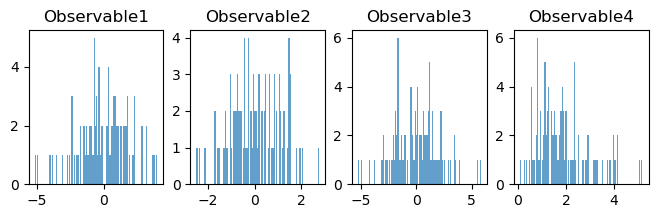

In [28]:
f = plt.figure(figsize=(8,2))
ax1, ax2, ax3, ax4 = plt.subplot(141), plt.subplot(142), plt.subplot(143), plt.subplot(144)

ax1.hist(obs1[:100], bins=100, alpha =0.7)
ax1.set_title("Observable1")

ax2.hist(obs2[:100], bins=100, alpha =0.7)
ax2.set_title("Observable2")

ax3.hist(obs3[:100], bins=100, alpha =0.7)
ax3.set_title("Observable3")

ax4.hist(obs4[:100], bins=100, alpha =0.7)
ax4.set_title("Observable4")

I observe four graphs with obscure, but semingly similar distribution looking data across the same range. The graphs have peaks, almost gaussian looking, but not for certain. Appears to be discrete. 

### Obs1 vs Obs2:

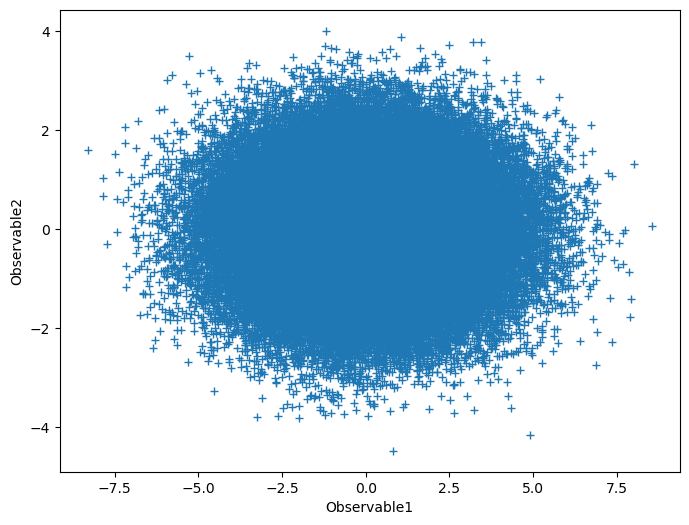

In [29]:
f = plt.figure(figsize=(8, 6))
ax = f.add_subplot(111)

ax.plot(obs1, obs2, ls='none', marker='+')
ax.set_xlabel("Observable1")
ax.set_ylabel("Observable2")

plt.show()

### Obs1 vs Obs3:

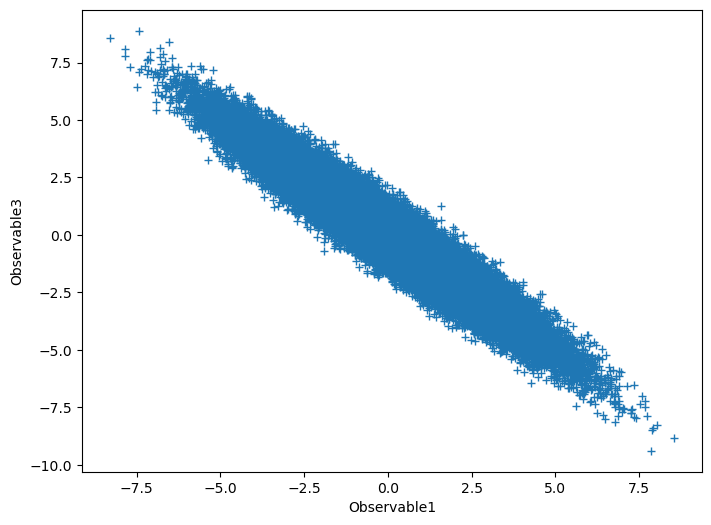

In [30]:
f = plt.figure(figsize=(8, 6))
ax = f.add_subplot(111)

ax.plot(obs1, obs3, ls='none', marker='+')
ax.set_xlabel("Observable1")
ax.set_ylabel("Observable3")

plt.show()

### Obs1 vs Obs4

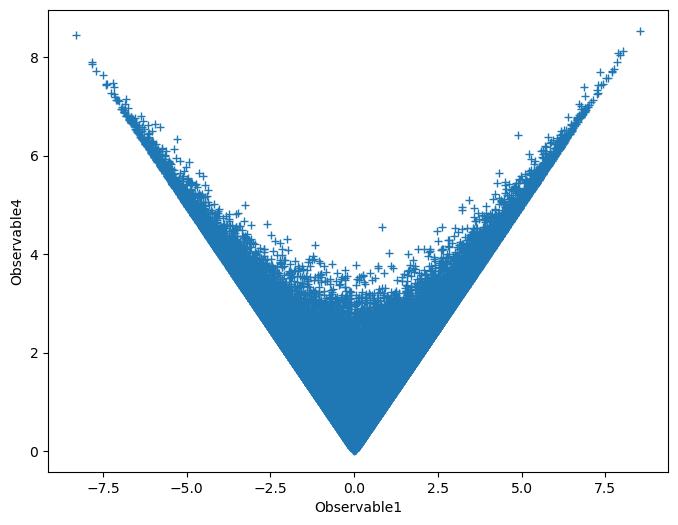

In [31]:
f = plt.figure(figsize=(8, 6))
ax = f.add_subplot(111)

ax.plot(obs1, obs4, ls='none', marker='+')
ax.set_xlabel("Observable1")
ax.set_ylabel("Observable4")

plt.show()

### Obs2 vs Obs3

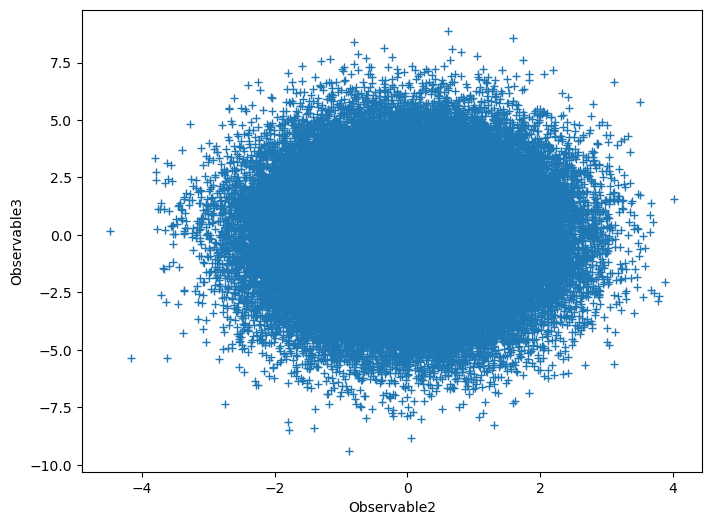

In [32]:
f = plt.figure(figsize=(8, 6))
ax = f.add_subplot(111)

ax.plot(obs2, obs3, ls='none', marker='+')
ax.set_xlabel("Observable2")
ax.set_ylabel("Observable3")

plt.show()

### Obs2 vs Obs4

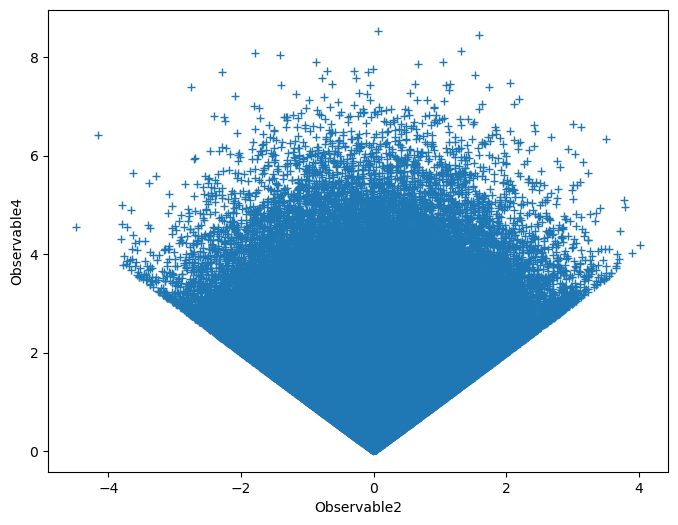

In [33]:
f = plt.figure(figsize=(8, 6))
ax = f.add_subplot(111)

ax.plot(obs2, obs4, ls='none', marker='+')
ax.set_xlabel("Observable2")
ax.set_ylabel("Observable4")

plt.show()

### Obs3 vs Obs4

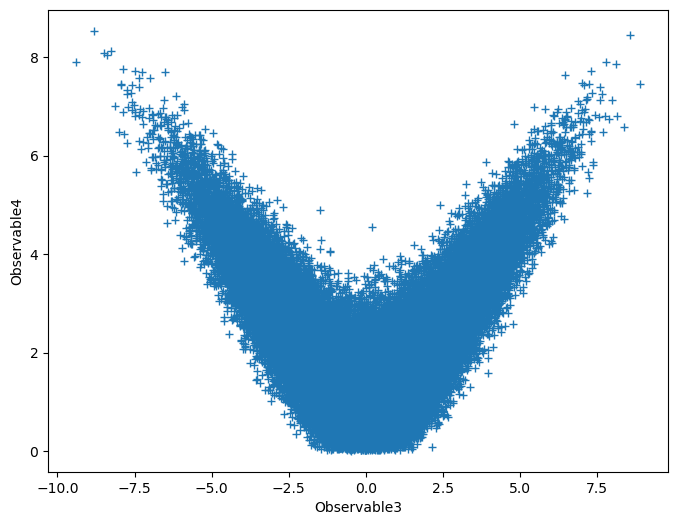

In [34]:
f = plt.figure(figsize=(8, 6))
ax = f.add_subplot(111)

ax.plot(obs3, obs4, ls='none', marker='+')
ax.set_xlabel("Observable3")
ax.set_ylabel("Observable4")

plt.show()

I would say for certain 1 and 3 are anticorrelated.

### The Stats

In [38]:
def stats(column):
    n = len(column)
    mean = (1/n) * np.sum(column)
    variance_sum = 0
    for i in column:
        variance_sum += (i - mean)**2
    variance = (1/(n-1)) * variance_sum
    print(f"Column: {column}, Mean: {mean}, Variance: {variance}")

for each in [obs1, obs2, obs3, obs4]:
    stats(each)

Column: [ 0.21430416 -0.55021236 -1.30634831 ... -2.67903154  2.80659935
 -0.25958039], Mean: 0.0033237207052143154, Variance: 3.9896701540928396
Column: [-1.50293888 -0.03891152  0.42381887 ...  0.09543108  1.37133628
  0.61312407], Mean: -0.0047418672484992016, Variance: 1.0112347670473207
Column: [-0.38748289  1.21057242  1.24138446 ...  2.21254515 -2.29947123
  1.18693276], Mean: -0.0008793368717326741, Variance: 4.346703818264439
Column: [1.51814082 0.55158658 1.37337845 ... 2.6807307  3.12370983 0.66581011], Mean: 1.9328425243565592, Variance: 1.265020870762933


In [39]:
def correlation(column1, column2):
    n1 = len(column1)
    n2 = len(column2)
    mean1 = (1/n1) * np.sum(column1)
    mean2 = (1/n2) * np.sum(column2)
    sum_xy = 0
    sum_x2 = 0
    sum_y2 = 0

    for x, y in zip(column1, column2):
        sum_xy += (x - mean1) * (y - mean2)
        sum_x2 += (x - mean1)**2
        sum_y2 += (y - mean2)**2

    correlation = sum_xy / np.sqrt(sum_x2 * sum_y2)

    return correlation


obs1_obs2_corr = correlation(obs1, obs2)
obs1_obs3_corr = correlation(obs1, obs3)
obs1_obs4_corr = correlation(obs1, obs4)
obs2_obs3_corr = correlation(obs2, obs3)
obs2_obs4_corr = correlation(obs2, obs4)
obs3_obs4_corr = correlation(obs3, obs4)

print(f"Obs 1 and Obs 2 Correlation Value: {obs1_obs2_corr}")
print(f"Obs 1 and Obs 3 Correlation Value: {obs1_obs3_corr}")
print(f"Obs 1 and Obs 4 Correlation Value: {obs1_obs4_corr}")
print(f"Obs 2 and Obs 3 Correlation Value: {obs2_obs3_corr}")
print(f"Obs 2 and Obs 4 Correlation Value: {obs2_obs4_corr}")
print(f"Obs 3 and Obs 4 Correlation Value: {obs3_obs4_corr}")

Obs 1 and Obs 2 Correlation Value: -0.00040440595033717006
Obs 1 and Obs 3 Correlation Value: -0.9578139876326974
Obs 1 and Obs 4 Correlation Value: 0.003997739674796835
Obs 2 and Obs 3 Correlation Value: 0.0016435912558260461
Obs 2 and Obs 4 Correlation Value: -0.0027733779183982577
Obs 3 and Obs 4 Correlation Value: -0.002429307631652713


So 1 and 3 definitely strongly anticorrelated.
Obs1 and Obs4 + Obs3 and Obs4 appear to be uncorrelated, but dependent. 